# 🛋️ E-commerce Furniture Dataset 2024 — Predicting Units Sold
**Tools:** Python · pandas · scikit-learn · matplotlib · seaborn  
**Objective:** Predict the number of furniture items sold (`sold`) from `productTitle`, `originalPrice`, `price` and `tagText`, and understand what drives sales on AliExpress.

**Steps**
1. Data Collection  2. Data Preprocessing  3. Exploratory Data Analysis  4. Feature Engineering  5. Model Selection & Training  6. Model Evaluation  7. Conclusion

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight'})

DATA_PATH = 'ecommerce_furniture_dataset_2024.csv'
IMG_DIR = 'images'
os.makedirs(IMG_DIR, exist_ok=True)

def save(name):
    plt.savefig(f'{IMG_DIR}/{name}.png', dpi=130)
    plt.show()

## 1. Data Collection

In [2]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
print('Shape:', df.shape)
df.head()

Shape: (2000, 5)


,productTitle,originalPrice,price,sold,tagText
0,Dresser For Bedroom With 9 Fabric Drawers Ward...,NaN,$46.79,600,Free shipping
1,Outdoor Conversation Set 4 Pieces Patio Furnit...,NaN,$169.72,0,Free shipping
2,Desser For Bedroom With 7 Fabric Drawers Organ...,$78.4,$39.46,7,Free shipping
3,"Modern Accent Boucle Chair,Upholstered Tufted ...",NaN,$111.99,0,Free shipping
4,Small Unit Simple Computer Desk Household Wood...,$48.82,$21.37,1,Free shipping


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   productTitle   2000 non-null   str  
 1   originalPrice  487 non-null    str  
 2   price          2000 non-null   str  
 3   sold           2000 non-null   int64
 4   tagText        1997 non-null   str  
dtypes: int64(1), str(4)
memory usage: 78.3 KB


## 2. Data Preprocessing
Checking missing values, cleaning the price columns (`$1,294.04` → `1294.04`), and handling `tagText`.

In [4]:
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('Missing originalPrice: %.1f%%' % (df['originalPrice'].isnull().mean()*100))

productTitle        0
originalPrice    1513
price               0
sold                0
tagText             3
dtype: int64

Duplicate rows: 94
Missing originalPrice: 75.6%


**Decision:** exact duplicate listings are removed. If the same row appears in both the train and test sets, the test score would be artificially inflated (data leakage).

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Shape after removing duplicates: (1906, 5)


**Decision:** The PDF template uses `dropna()`, but `originalPrice` is missing for ~76% of rows (these items are simply *not discounted*), so dropping would delete most of the data. Instead we keep every row and create a `has_discount` flag.

In [6]:
def to_float(s):
    return pd.to_numeric(s.astype(str).str.replace(r'[\$,]', '', regex=True), errors='coerce')

df['price'] = to_float(df['price'])
df['originalPrice'] = to_float(df['originalPrice'])

# tagText: "Free shipping" or "+Shipping: $5.09" (3 rows missing -> 'Unknown')
df['tagText'] = df['tagText'].fillna('Unknown')
df['shipping_cost'] = np.where(df['tagText'].str.contains(r'\+Shipping', na=False),
                               to_float(df['tagText'].str.extract(r'\$([\d,\.]+)')[0]), 0.0)
df['shipping_type'] = np.select(
    [df['tagText'].eq('Free shipping'), df['tagText'].str.contains(r'\+Shipping'), ],
    ['Free shipping', 'Paid shipping'], default='Unknown')

print(df[['price','originalPrice','sold','shipping_cost']].describe().round(2))
print()
print(df['shipping_type'].value_counts())

         price  originalPrice      sold  shipping_cost
count  1906.00         470.00   1906.00        1906.00
mean    154.36         249.49     24.45           7.63
std     176.97         418.75    260.25          58.64
min       0.99           3.63      0.00           0.00
25%      47.46          31.20      1.00           0.00
50%     112.48          87.16      3.00           0.00
75%     191.54         304.06      9.75           0.00
max    2876.38        3265.13  10000.00        1323.31

shipping_type
Free shipping    1789
Paid shipping     115
Unknown             2
Name: count, dtype: int64


In [7]:
# Sanity check: discounted price should be below original price
bad = df[(df['originalPrice'].notna()) & (df['originalPrice'] < df['price'])]
print('Rows where originalPrice < price:', len(bad))
df.to_csv('cleaned_furniture_dataset.csv', index=False)

Rows where originalPrice < price: 0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of `sold`
`sold` is extremely right-skewed: most products sell only a handful of units while a few sell thousands. A log scale makes the shape visible.

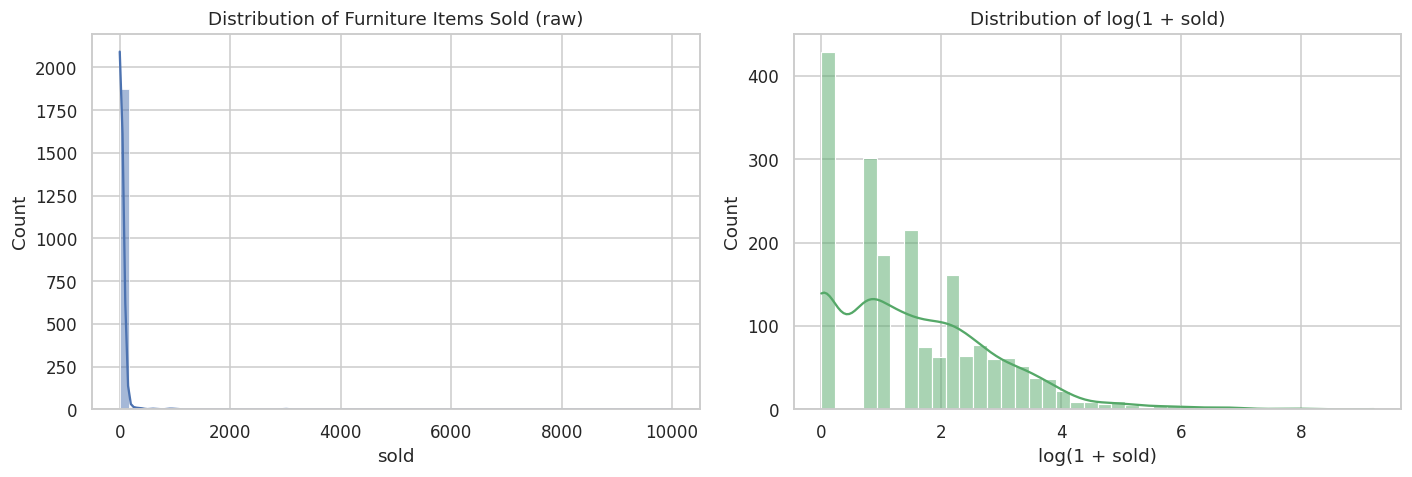

Products with 0 sales: 22.5%
Median sold: 3.0 | Mean sold: 24.4 | Max: 10000


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['sold'], bins=60, kde=True, ax=ax[0], color='#4C72B0')
ax[0].set_title('Distribution of Furniture Items Sold (raw)')
sns.histplot(np.log1p(df['sold']), bins=40, kde=True, ax=ax[1], color='#55A868')
ax[1].set_title('Distribution of log(1 + sold)')
ax[1].set_xlabel('log(1 + sold)')
plt.tight_layout(); save('01_sold_distribution')
print('Products with 0 sales: %.1f%%' % ((df.sold==0).mean()*100))
print('Median sold:', df.sold.median(), '| Mean sold: %.1f' % df.sold.mean(), '| Max:', df.sold.max())

### 3.2 Distribution of `price`

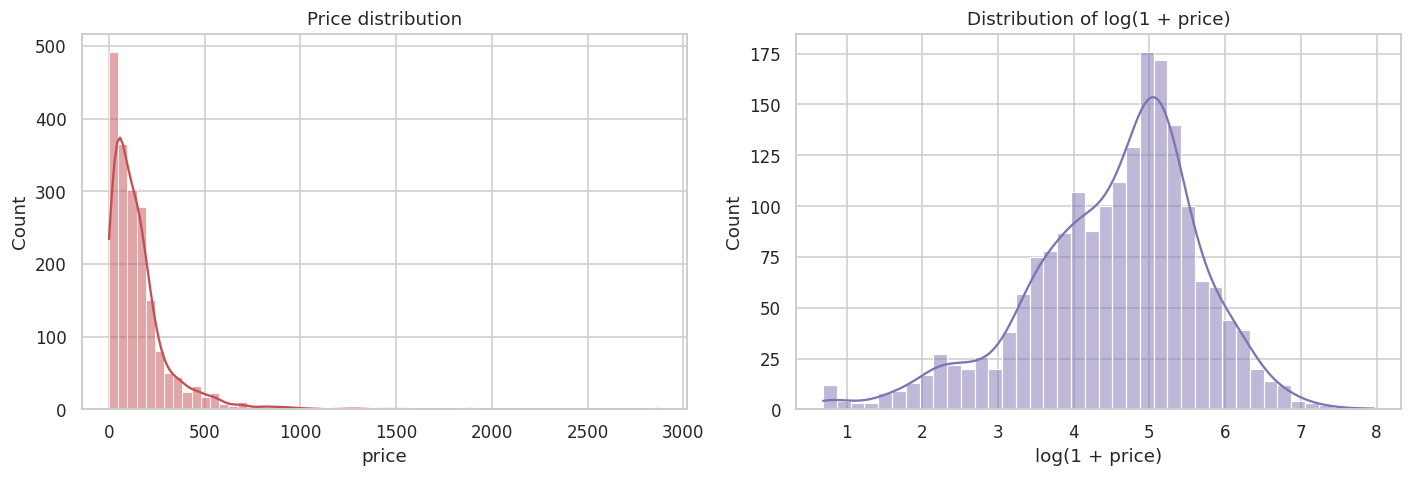

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['price'], bins=60, kde=True, ax=ax[0], color='#C44E52')
ax[0].set_title('Price distribution')
sns.histplot(np.log1p(df['price']), bins=40, kde=True, ax=ax[1], color='#8172B2')
ax[1].set_title('Distribution of log(1 + price)'); ax[1].set_xlabel('log(1 + price)')
plt.tight_layout(); save('02_price_distribution')

### 3.3 Shipping tag (`tagText`)

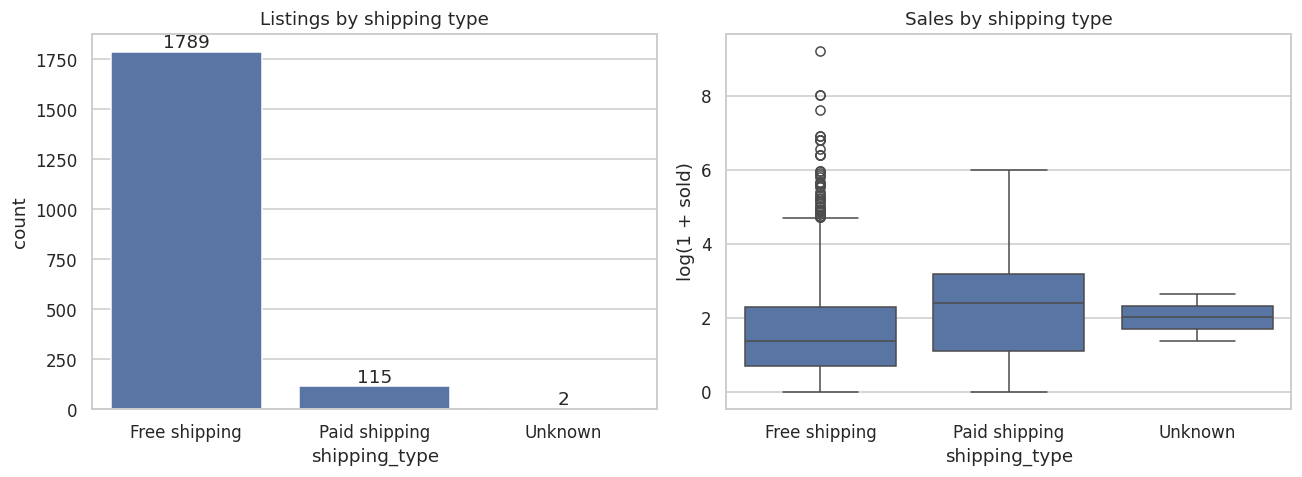

               count  mean  median    sum
shipping_type                            
Free shipping   1789  24.6     3.0  44080
Paid shipping    115  21.8    10.0   2505
Unknown            2   8.0     8.0     16


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
order = df['shipping_type'].value_counts().index
sns.countplot(x='shipping_type', data=df, order=order, ax=ax[0])
ax[0].set_title('Listings by shipping type')
for c in ax[0].containers: ax[0].bar_label(c)
sns.boxplot(x='shipping_type', y=np.log1p(df['sold']), data=df, order=order, ax=ax[1])
ax[1].set_ylabel('log(1 + sold)'); ax[1].set_title('Sales by shipping type')
plt.tight_layout(); save('03_shipping_type')
print(df.groupby('shipping_type')['sold'].agg(['count','mean','median','sum']).round(1))

### 3.4 Price vs Sold

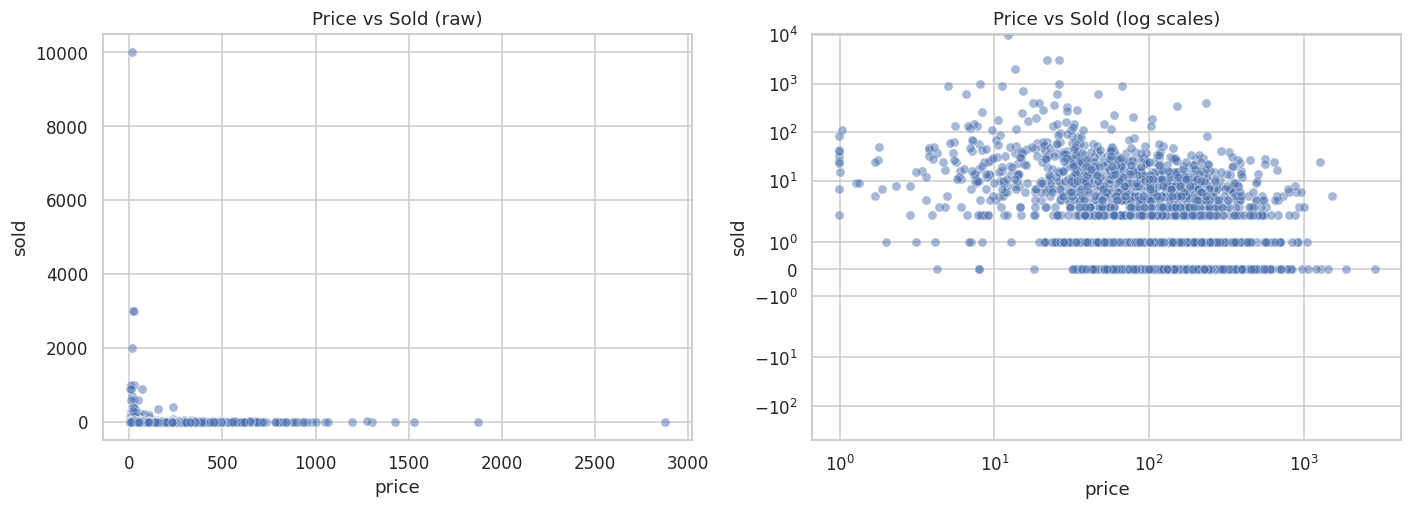

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(x='price', y='sold', data=df, alpha=.5, ax=ax[0])
ax[0].set_title('Price vs Sold (raw)')
sns.scatterplot(x='price', y='sold', data=df, alpha=.5, ax=ax[1])
ax[1].set_xscale('log'); ax[1].set_yscale('symlog')
ax[1].set_title('Price vs Sold (log scales)')
plt.tight_layout(); save('04_price_vs_sold')

            count   mean  median    sum
price_band                             
<$25          226  116.9    14.0  26429
$25-50        274   38.4     8.0  10516
$50-100       372   11.9     3.0   4417
$100-200      596    5.3     2.0   3168
$200-500      363    5.0     1.0   1829
>$500          75    3.2     1.0    242


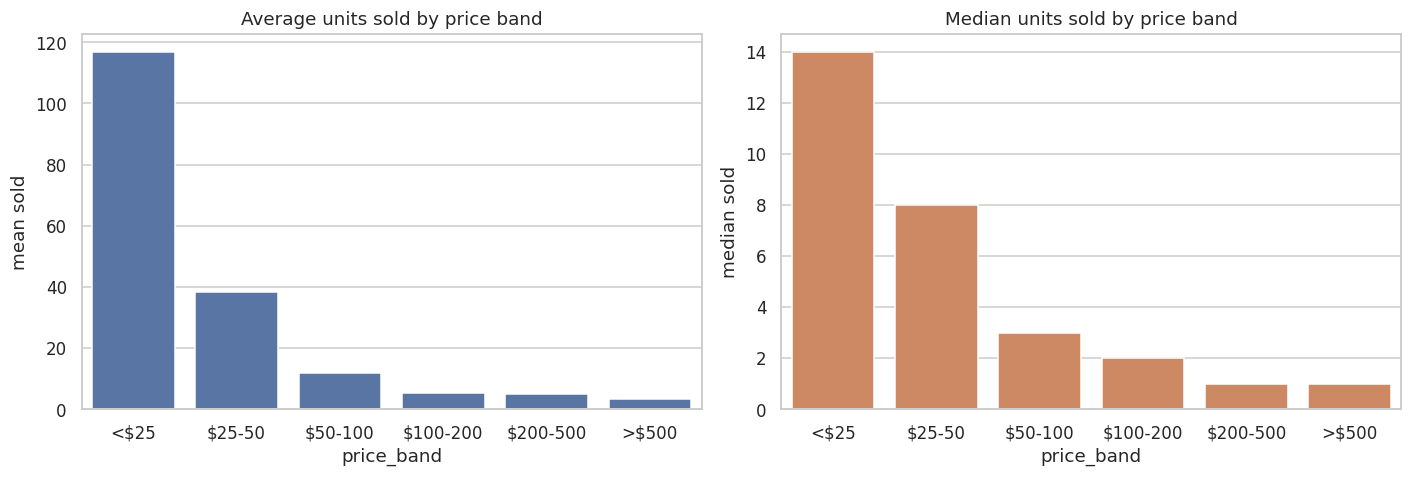

In [12]:
df['price_band'] = pd.cut(df['price'], bins=[0,25,50,100,200,500,10000],
                          labels=['<$25','$25-50','$50-100','$100-200','$200-500','>$500'])
band = df.groupby('price_band', observed=True)['sold'].agg(['count','mean','median','sum'])
print(band.round(1))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=band.index, y=band['mean'], ax=ax[0], color='#4C72B0'); ax[0].set_title('Average units sold by price band'); ax[0].set_ylabel('mean sold')
sns.barplot(x=band.index, y=band['median'], ax=ax[1], color='#DD8452'); ax[1].set_title('Median units sold by price band'); ax[1].set_ylabel('median sold')
plt.tight_layout(); save('05_price_band_sales')

### 3.5 Impact of discounts

              count   mean  median
has_discount                      
0              1436   6.88     2.0
1               470  78.13    10.0


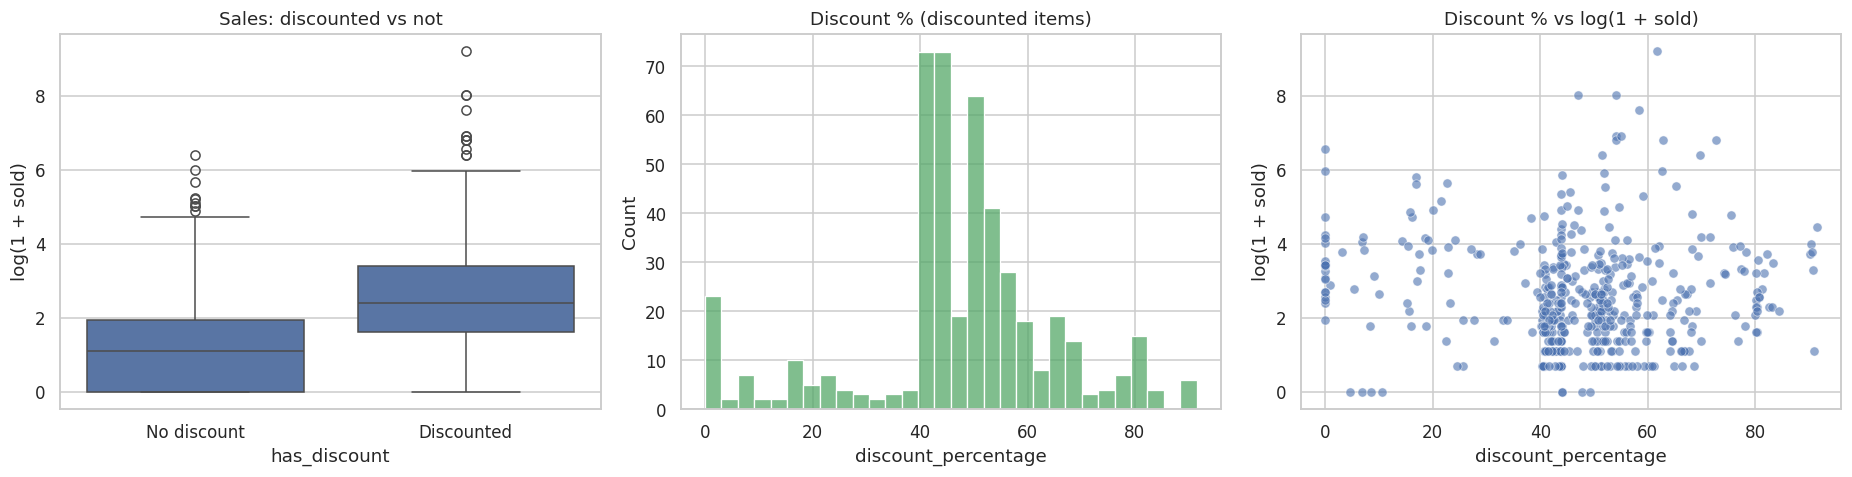

In [13]:
df['has_discount'] = df['originalPrice'].notna().astype(int)
df['discount_percentage'] = ((df['originalPrice'] - df['price']) / df['originalPrice'] * 100).fillna(0).clip(lower=0)

print(df.groupby('has_discount')['sold'].agg(['count','mean','median']).round(2))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(x='has_discount', y=np.log1p(df['sold']), data=df, ax=ax[0])
ax[0].set_title('Sales: discounted vs not'); ax[0].set_xticklabels(['No discount','Discounted']); ax[0].set_ylabel('log(1 + sold)')
sns.histplot(df.loc[df.has_discount==1,'discount_percentage'], bins=30, ax=ax[1], color='#55A868')
ax[1].set_title('Discount % (discounted items)')
d = df[df.has_discount==1]
sns.scatterplot(x='discount_percentage', y=np.log1p(d['sold']), data=d, alpha=.6, ax=ax[2])
ax[2].set_title('Discount % vs log(1 + sold)'); ax[2].set_ylabel('log(1 + sold)')
plt.tight_layout(); save('06_discount_analysis')

### 3.6 Which words in titles go with higher sales?

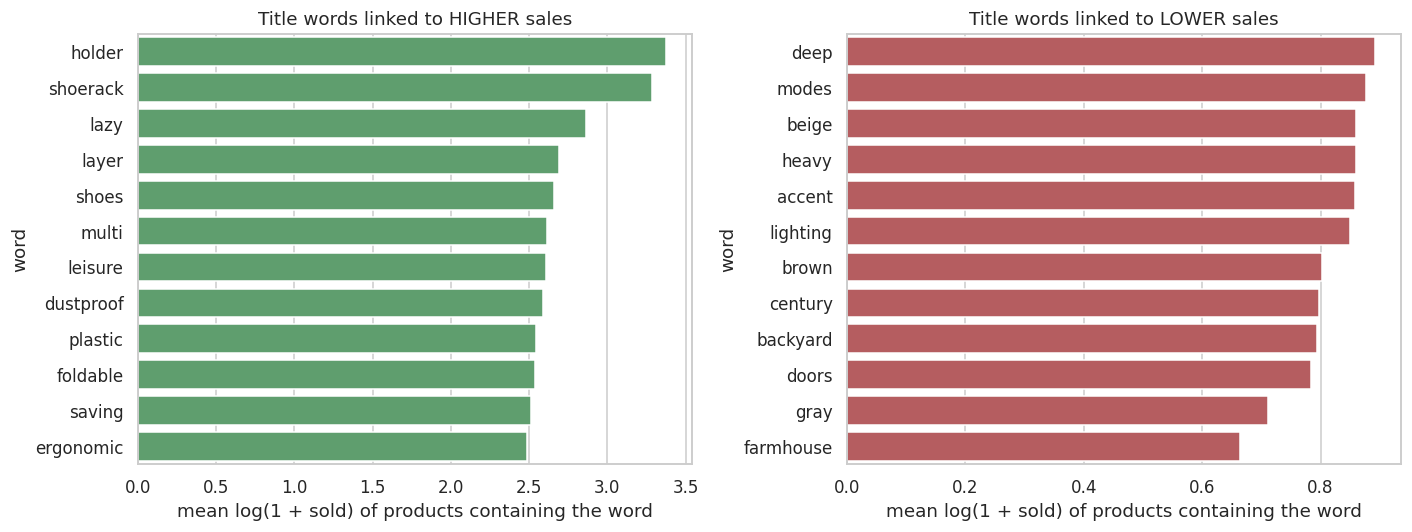

,word,n_products,median_sold,mean_log_sold
89,holder,25,21.0,3.373114
160,shoerack,35,37.0,3.285766
96,lazy,43,16.0,2.861187
95,layer,40,15.0,2.687642
161,shoes,60,14.5,2.660927
120,multi,46,12.0,2.615470
100,leisure,27,18.0,2.607141
58,dustproof,33,11.0,2.587353
138,plastic,51,14.0,2.543047
68,foldable,40,8.5,2.536770


In [14]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(stop_words='english', min_df=25, binary=True)
Xw = cv.fit_transform(df['productTitle'].str.lower())
words = cv.get_feature_names_out()
rows = []
for i, w in enumerate(words):
    m = Xw[:, i].toarray().ravel() == 1
    rows.append((w, m.sum(), df.loc[m,'sold'].median(), np.log1p(df.loc[m,'sold']).mean()))
wd = pd.DataFrame(rows, columns=['word','n_products','median_sold','mean_log_sold']).sort_values('mean_log_sold', ascending=False)
top = wd.head(12); bot = wd.tail(12)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(y='word', x='mean_log_sold', data=top, ax=ax[0], color='#55A868'); ax[0].set_title('Title words linked to HIGHER sales')
sns.barplot(y='word', x='mean_log_sold', data=bot, ax=ax[1], color='#C44E52'); ax[1].set_title('Title words linked to LOWER sales')
for a in ax: a.set_xlabel('mean log(1 + sold) of products containing the word')
plt.tight_layout(); save('07_title_keywords')
wd.head(12)

### 3.7 Top sellers and correlations

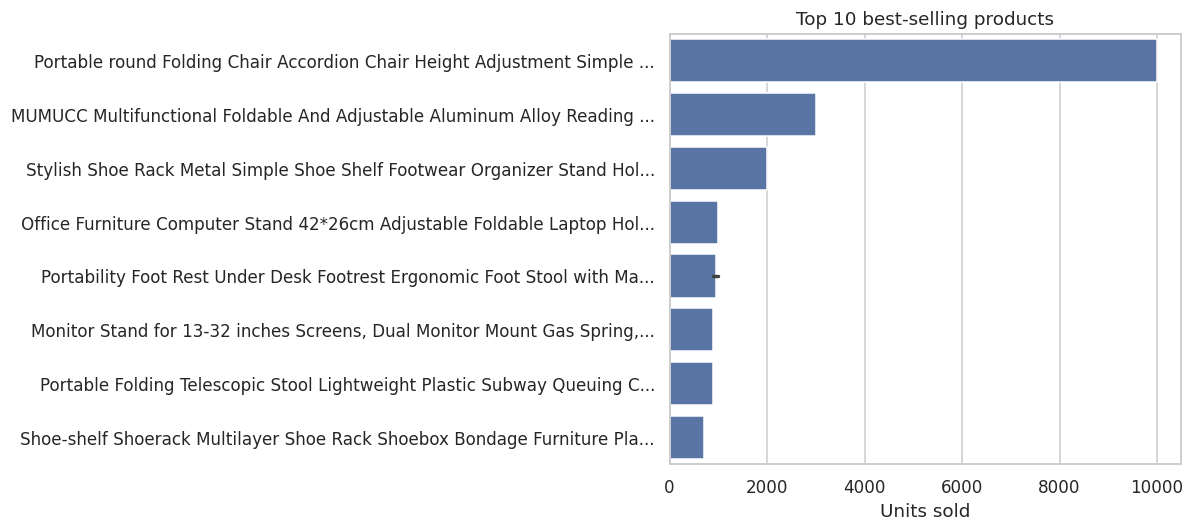

,productTitle,price,sold,tagText
975,Portable round Folding Chair Accordion Chair H...,12.28,10000,Free shipping
666,MUMUCC Multifunctional Foldable And Adjustable...,26.11,3000,Free shipping
1357,MUMUCC Multifunctional Foldable And Adjustable...,21.94,3000,Free shipping
988,Stylish Shoe Rack Metal Simple Shoe Shelf Foot...,13.64,2000,Free shipping
22,Office Furniture Computer Stand 42*26cm Adjust...,26.03,1000,Free shipping
1141,Portability Foot Rest Under Desk Footrest Ergo...,8.04,1000,Free shipping
663,Portability Foot Rest Under Desk Footrest Ergo...,5.00,900,Free shipping
983,"Monitor Stand for 13-32 inches Screens, Dual M...",66.68,900,Free shipping
1475,Portable Folding Telescopic Stool Lightweight ...,11.20,900,Free shipping
468,Shoe-shelf Shoerack Multilayer Shoe Rack Shoeb...,15.40,700,Free shipping


In [15]:
top10 = df.nlargest(10, 'sold')[['productTitle','price','sold','tagText']].copy()
top10['productTitle'] = top10['productTitle'].str.slice(0, 70) + '...'
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(y=top10['productTitle'], x=top10['sold'], ax=ax, color='#4C72B0')
ax.set_title('Top 10 best-selling products'); ax.set_xlabel('Units sold'); ax.set_ylabel('')
plt.tight_layout(); save('08_top10_products')
top10

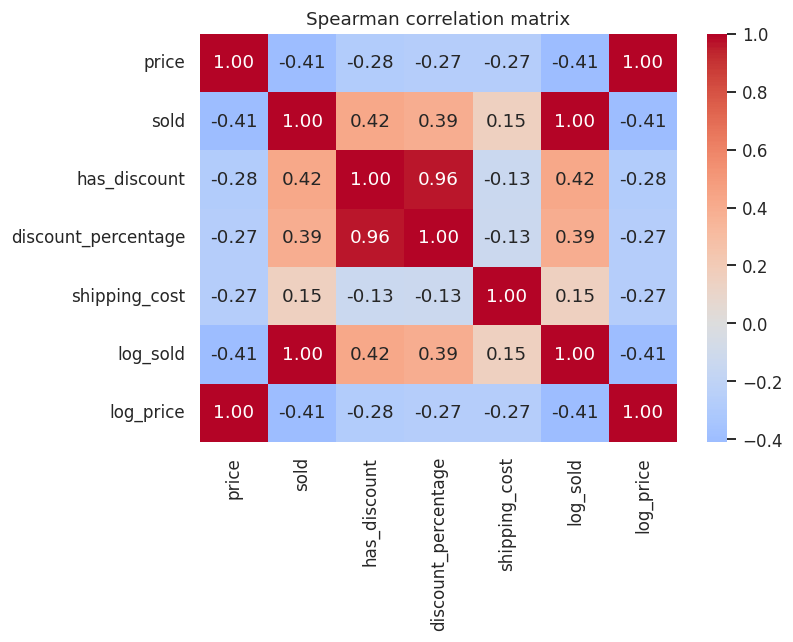

In [16]:
corr_df = df[['price','sold','has_discount','discount_percentage','shipping_cost']].copy()
corr_df['log_sold'] = np.log1p(corr_df['sold']); corr_df['log_price'] = np.log1p(corr_df['price'])
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_df.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman correlation matrix'); plt.tight_layout(); save('09_correlation_heatmap')

## 4. Feature Engineering
* `discount_percentage` and `has_discount` (from `originalPrice` and `price`)
* `log_price`, `shipping_cost`, one-hot shipping type
* Title length and word count
* **TF-IDF** (100 features) from `productTitle`

**Target:** `sold` is heavily skewed (max 10,000 vs median 3), so we train on `log1p(sold)` and convert predictions back with `expm1` for reporting.

In [17]:
df['title_len'] = df['productTitle'].str.len()
df['title_words'] = df['productTitle'].str.split().str.len()
df['log_price'] = np.log1p(df['price'])
ship = pd.get_dummies(df['shipping_type'], prefix='ship', dtype=int)

tfidf = TfidfVectorizer(max_features=100, stop_words='english')
T = tfidf.fit_transform(df['productTitle'])
tfidf_df = pd.DataFrame(T.toarray(), columns=['tf_' + w for w in tfidf.get_feature_names_out()], index=df.index)

num_cols = ['price','log_price','has_discount','discount_percentage','shipping_cost','title_len','title_words']
X = pd.concat([df[num_cols], ship, tfidf_df], axis=1)
y = df['sold']; y_log = np.log1p(y)
print('Feature matrix:', X.shape)

Feature matrix: (1906, 110)


## 5. Model Selection & Training
80/20 train-test split (`random_state=42`). Models: Linear Regression and Random Forest (as in the guide), plus Gradient Boosting and a mean-predictor baseline for context.

In [18]:
X_train, X_test, ytr_log, yte_log = train_test_split(X, y_log, test_size=0.2, random_state=42)
y_test = np.expm1(yte_log)

models = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=.8, random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(X_train, ytr_log)
    preds[name] = m.predict(X_test)
print('Trained:', list(models))

Trained: ['Baseline (mean)', 'Linear Regression', 'Random Forest', 'Gradient Boosting']


## 6. Model Evaluation
Metrics are reported on the **log scale** (the scale the models are trained on) and on the **original units-sold scale**. The raw-scale MSE is dominated by a few extreme sellers (e.g. 10,000 units), so the log-scale numbers are the fairer comparison.

In [19]:
rows = []
for name, p in preds.items():
    p_units = np.clip(np.expm1(p), 0, None)
    rows.append({
        'Model': name,
        'MSE (log)': mean_squared_error(yte_log, p),
        'RMSE (log)': np.sqrt(mean_squared_error(yte_log, p)),
        'MAE (log)': mean_absolute_error(yte_log, p),
        'R2 (log)': r2_score(yte_log, p),
        'MSE (units)': mean_squared_error(y_test, p_units),
        'MAE (units)': mean_absolute_error(y_test, p_units),
        'R2 (units)': r2_score(y_test, p_units),
    })
results = pd.DataFrame(rows).set_index('Model').round(3)
results.to_csv('model_results.csv')
results

,MSE (log),RMSE (log),MAE (log),R2 (log),MSE (units),MAE (units),R2 (units)
Model,,,,,,,
Baseline (mean),1.715,1.309,1.072,-0.000,13110.945,16.806,-0.015
Linear Regression,1.195,1.093,0.861,0.302,12715.963,15.486,0.015
Random Forest,1.080,1.039,0.814,0.370,12797.899,15.106,0.009
Gradient Boosting,1.099,1.048,0.817,0.359,12828.996,15.190,0.007


In [20]:
print(f"Linear Regression  -> MSE(log): {results.loc['Linear Regression','MSE (log)']}, R2(log): {results.loc['Linear Regression','R2 (log)']}")
print(f"Random Forest      -> MSE(log): {results.loc['Random Forest','MSE (log)']}, R2(log): {results.loc['Random Forest','R2 (log)']}")
print(f"Gradient Boosting  -> MSE(log): {results.loc['Gradient Boosting','MSE (log)']}, R2(log): {results.loc['Gradient Boosting','R2 (log)']}")

Linear Regression  -> MSE(log): 1.195, R2(log): 0.302
Random Forest      -> MSE(log): 1.08, R2(log): 0.37
Gradient Boosting  -> MSE(log): 1.099, R2(log): 0.359


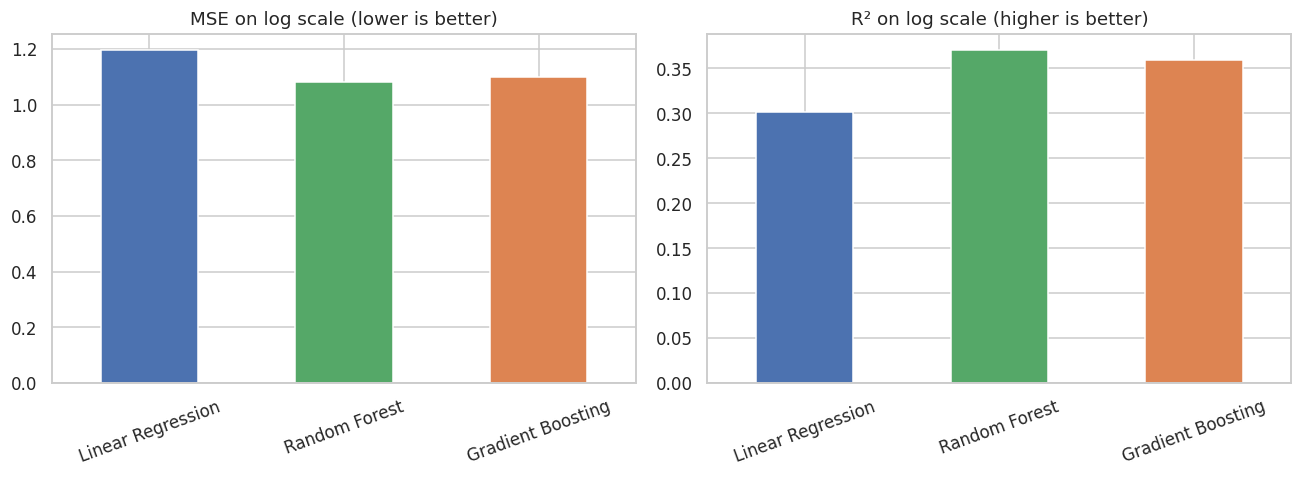

In [21]:
plot_res = results.drop('Baseline (mean)')
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_res['MSE (log)'].plot(kind='bar', ax=ax[0], color=['#4C72B0','#55A868','#DD8452']); ax[0].set_title('MSE on log scale (lower is better)')
plot_res['R2 (log)'].plot(kind='bar', ax=ax[1], color=['#4C72B0','#55A868','#DD8452']); ax[1].set_title('R² on log scale (higher is better)')
ax[1].axhline(0, color='k', lw=.8)
for a in ax: a.set_xlabel(''); a.tick_params(axis='x', rotation=20)
plt.tight_layout(); save('10_model_comparison')

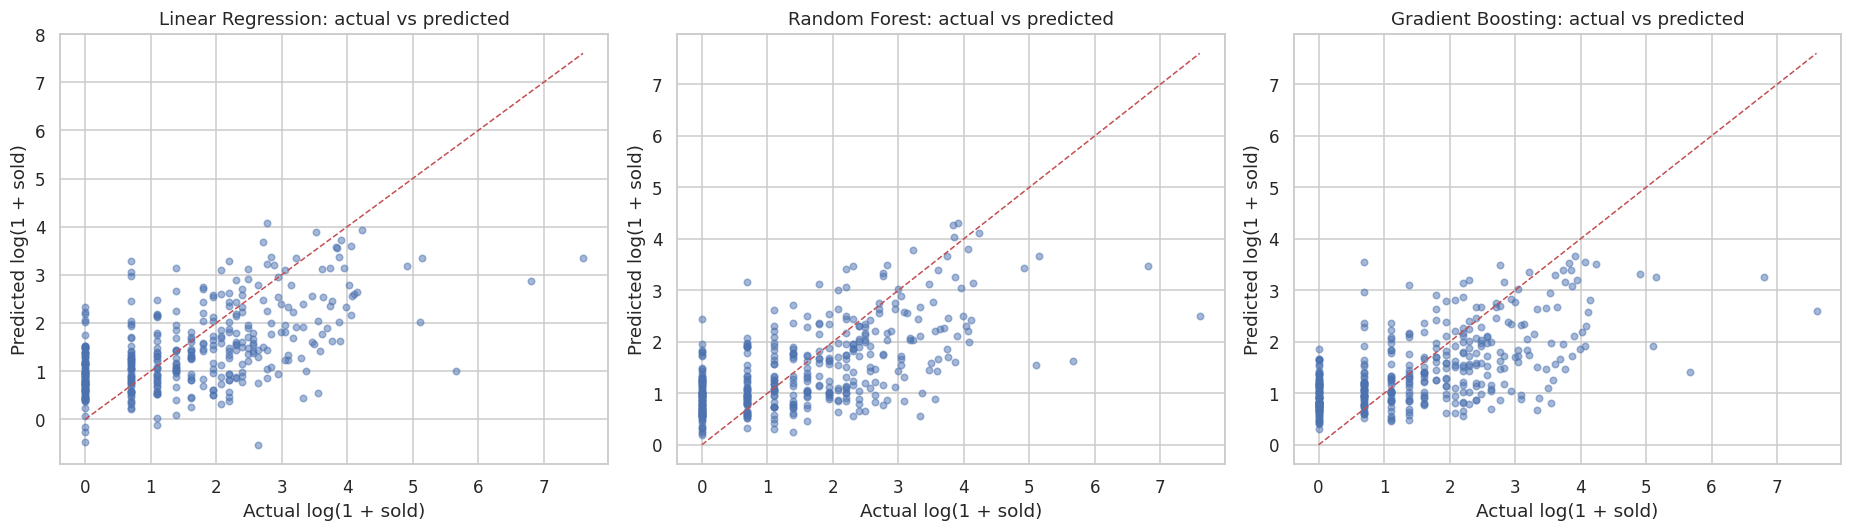

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, name in zip(ax, ['Linear Regression','Random Forest','Gradient Boosting']):
    a.scatter(yte_log, preds[name], alpha=.5, s=18)
    lim = [0, max(yte_log.max(), preds[name].max())]
    a.plot(lim, lim, 'r--', lw=1)
    a.set_title(f'{name}: actual vs predicted'); a.set_xlabel('Actual log(1 + sold)'); a.set_ylabel('Predicted log(1 + sold)')
plt.tight_layout(); save('11_actual_vs_predicted')

Best model by log-scale R²: Random Forest


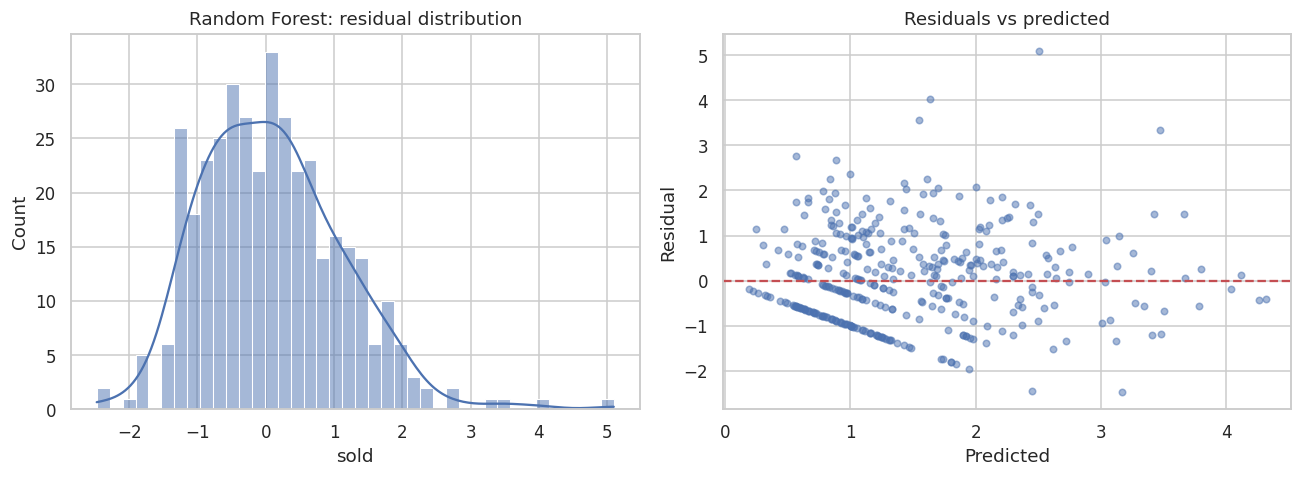

In [23]:
best = results.drop('Baseline (mean)')['R2 (log)'].idxmax()
print('Best model by log-scale R²:', best)
res = yte_log - preds[best]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(res, bins=40, kde=True, ax=ax[0]); ax[0].set_title(f'{best}: residual distribution')
ax[1].scatter(preds[best], res, alpha=.5, s=18); ax[1].axhline(0, color='r', ls='--')
ax[1].set_title('Residuals vs predicted'); ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual')
plt.tight_layout(); save('12_residuals')

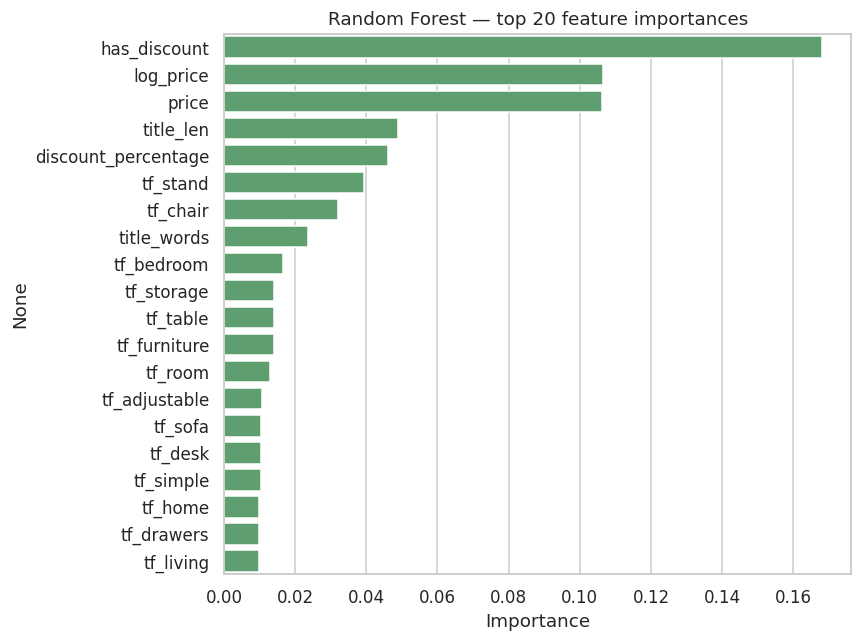

,importance
has_discount,0.1679
log_price,0.1064
price,0.1064
title_len,0.0488
discount_percentage,0.0461
tf_stand,0.0393
tf_chair,0.0320
title_words,0.0236
tf_bedroom,0.0165
tf_storage,0.0142


In [24]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(20)
plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color='#55A868')
plt.title('Random Forest — top 20 feature importances'); plt.xlabel('Importance')
plt.tight_layout(); save('13_feature_importance')
imp.round(4).to_frame('importance')

## 7. Conclusion

In [25]:
bl = results.loc['Baseline (mean)','R2 (log)']
print('Findings')
print('-'*60)
print(f"1. {(df.sold==0).mean()*100:.0f}% of listings have zero sales; median sold = {df.sold.median():.0f}, mean = {df.sold.mean():.1f} (driven by a few viral items).")
print(f"2. {(df.shipping_type=='Free shipping').mean()*100:.0f}% of listings offer free shipping.")
print(f"3. Discounted listings: median sold {df[df.has_discount==1].sold.median():.0f} vs {df[df.has_discount==0].sold.median():.0f} for non-discounted.")
print(f"4. Best model: {best} (log-scale R² = {results.loc[best,'R2 (log)']}, baseline = {bl}).")
print(f"5. Most important features: {', '.join(imp.index[:5])}")

Findings
------------------------------------------------------------
1. 23% of listings have zero sales; median sold = 3, mean = 24.4 (driven by a few viral items).
2. 94% of listings offer free shipping.
3. Discounted listings: median sold 10 vs 2 for non-discounted.
4. Best model: Random Forest (log-scale R² = 0.37, baseline = -0.0).
5. Most important features: has_discount, log_price, price, title_len, discount_percentage
